In [1]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


In [2]:
df = pd.read_csv('Advertising.csv')
if 'unnamed: 0' in df.columns:
    df = df.drop(columns=['unnamed: 0'])
    df.head()

Dataset Shape: (200, 5)

Null Values:
 Unnamed: 0    0
TV            0
Radio         0
Newspaper     0
Sales         0
dtype: int64

Stats:
        Unnamed: 0          TV       Radio   Newspaper       Sales
count  200.000000  200.000000  200.000000  200.000000  200.000000
mean   100.500000  147.042500   23.264000   30.554000   14.022500
std     57.879185   85.854236   14.846809   21.778621    5.217457
min      1.000000    0.700000    0.000000    0.300000    1.600000
25%     50.750000   74.375000    9.975000   12.750000   10.375000
50%    100.500000  149.750000   22.900000   25.750000   12.900000
75%    150.250000  218.825000   36.525000   45.100000   17.400000
max    200.000000  296.400000   49.600000  114.000000   27.000000


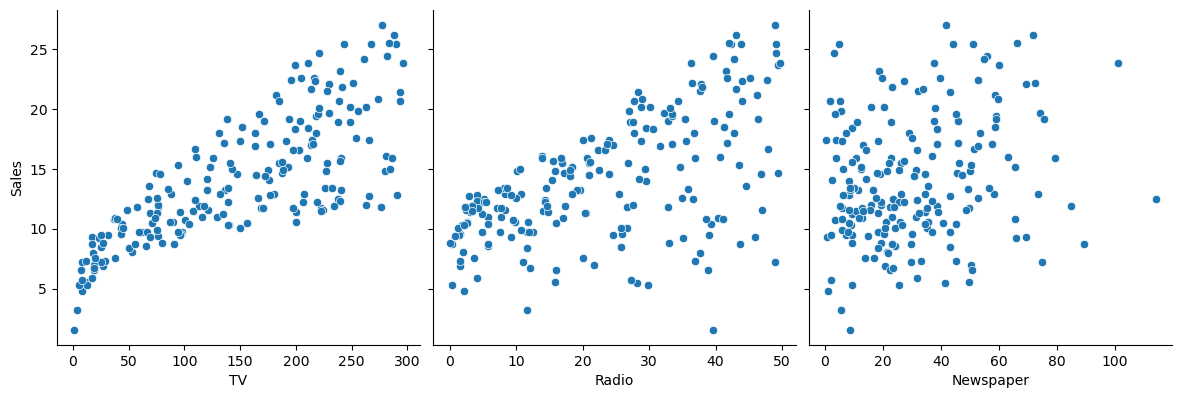

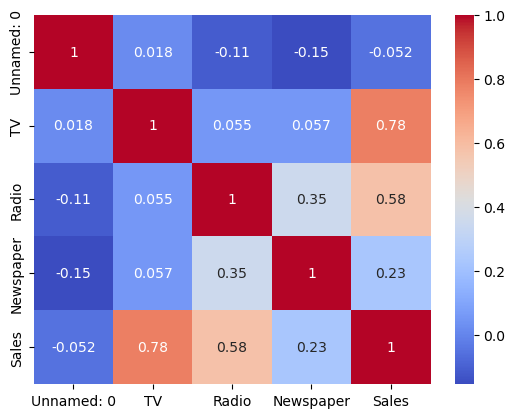

In [3]:
print("Dataset Shape:",df.shape)
print("\nNull Values:\n",df.isnull().sum())
print("\nStats:\n",df.describe())

sns.pairplot(df,x_vars=['TV','Radio','Newspaper'],y_vars='Sales',height=4,aspect=1,kind='scatter')
plt.show()

sns.heatmap(df.corr(),annot=True,cmap='coolwarm')
plt.show()

In [4]:
X = df[['TV','Radio','Newspaper']]
y = df['Sales']

X_train,X_test,y_train,y_test = train_test_split(X, y, test_size=0.2,random_state=42)

In [5]:
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)
lr_preds = lr_model.predict(X_test)

rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)
rf_preds = rf_model.predict(X_test)

In [6]:
def evaluate(y_true, y_pred, name):
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)

    print(f"---{name} ---")
    print(f"MAE: {mae:.2f}")
    print(f"RMSE: {rmse:.2f}")
    print(f"R2 Score: {r2:.2f}\n")
    
evaluate(y_test, lr_preds, "Linear Regression")
evaluate(y_test, rf_preds, "Random Forest Regressor")
coefficients = pd.DataFrame(lr_model.coef_, X.columns, columns=['Coefficient'])
print("Feature Impact on Sales:")
print(coefficients)

---Linear Regression ---
MAE: 1.46
RMSE: 1.78
R2 Score: 0.90

---Random Forest Regressor ---
MAE: 0.62
RMSE: 0.77
R2 Score: 0.98

Feature Impact on Sales:
           Coefficient
TV            0.044730
Radio         0.189195
Newspaper     0.002761
